# Exploratory Data Analysis: U.S. Honey Prices

**Data from:** `data/honey-price-index.csv` (from rawhoneyguide.com). It combines USDA reports on honey prices:
- **AMS** monthly bulk and import prices, July 2023 to August 2026
- **NASS** annual honey prices and production, 1998 to 2025

The `recordType` column indicates which USDA table a row came from. Different tables fill different columns, so many columns are empty for most rows, thus that is not an error

**Plan (following the NIST EDA handbook):** look at each variable alone, then all numeric variables together, then pairs of variables.

In [ ]:
# to install into the kernel the notebook is connected to, can ignore
%pip install seaborn pandas matplotlib

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

### Context:
- AMS — Agricultural Marketing Service. It’s the market reporter. Staff call buyers and sellers, ask what honey actually traded for this month, and publish a price range. That’s why AMS rows in the data have lowUsdPerLb and highUsdPerLb instead of one number. It’s the range of deals they heard about. The rows column is how many quotes went into that line. It is like a weekly grocery flyer showing what what is selling

- NASS — National Agricultural Statistics Service. It’s the census taker. It surveys beekeepers once a year and asks how much honey they produced and what average price they got. That’s why NASS rows have a single usdPerLb plus productionMlb.

## 1. Load the data

In [ ]:
df = pd.read_csv("data/honey-price-index.csv")
print(df.shape)
print(df.head())

In [ ]:
n_columns = df.shape[1]   # columns in the original file
df = df.drop(columns=["flags"])

# NASS rows use state abbreviations in 'state' and full names in 'stateName';
# AMS rows put full names in 'state'. Combine them into one column.
df["state_clean"] = df["stateName"].fillna(df["state"])

numeric_cols = ["lowUsdPerLb", "highUsdPerLb", "midUsdPerLb", "usdPerLb", "rows", "productionMlb"]
categorical_cols = ["recordType", "sourceHost", "state_clean", "country", "floral",
                    "floralSource", "grade", "colorClass", "channel", "lotBasis"]

print("Rows:", len(df))
print("Columns in the file:", n_columns)
print("Numeric columns with data:", len(numeric_cols))

**What the numeric columns mean**
- `lowUsdPerLb`, `highUsdPerLb`: low and high price per pound on an AMS report line
- `midUsdPerLb`: midpoint of the national bulk price (only 25 rows)
- `usdPerLb`: NASS average price per pound
- `rows`: number of price quotes behind an AMS line
- `productionMlb`: national honey production in million pounds (NASS, annual)

## 2. numeric variables

Outliers formula: 1.5 × IQR 

In [35]:
stats = df[numeric_cols].describe().T
stats["median"] = df[numeric_cols].median()

outliers = []
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low_fence = q1 - 1.5 * iqr
    high_fence = q3 + 1.5 * iqr
    n_out = ((df[col] < low_fence) | (df[col] > high_fence)).sum()
    outliers.append(n_out)
stats["outliers"] = outliers

print(stats[["count", "min", "mean", "median", "max", "std", "outliers"]].round(2))

                count     min    mean  median     max    std  outliers
lowUsdPerLb    1598.0    0.84    1.74    1.80    3.59   0.59         7
highUsdPerLb   1598.0    0.84    1.91    1.90    3.59   0.61         8
midUsdPerLb      25.0    1.90    2.36    2.33    3.04   0.24         1
usdPerLb       1522.0    0.49    2.22    1.89    8.94   1.43       104
rows            321.0    1.00    6.19    4.00   67.00   8.19        27
productionMlb    84.0  116.00  161.18  156.00  221.00  25.92         6


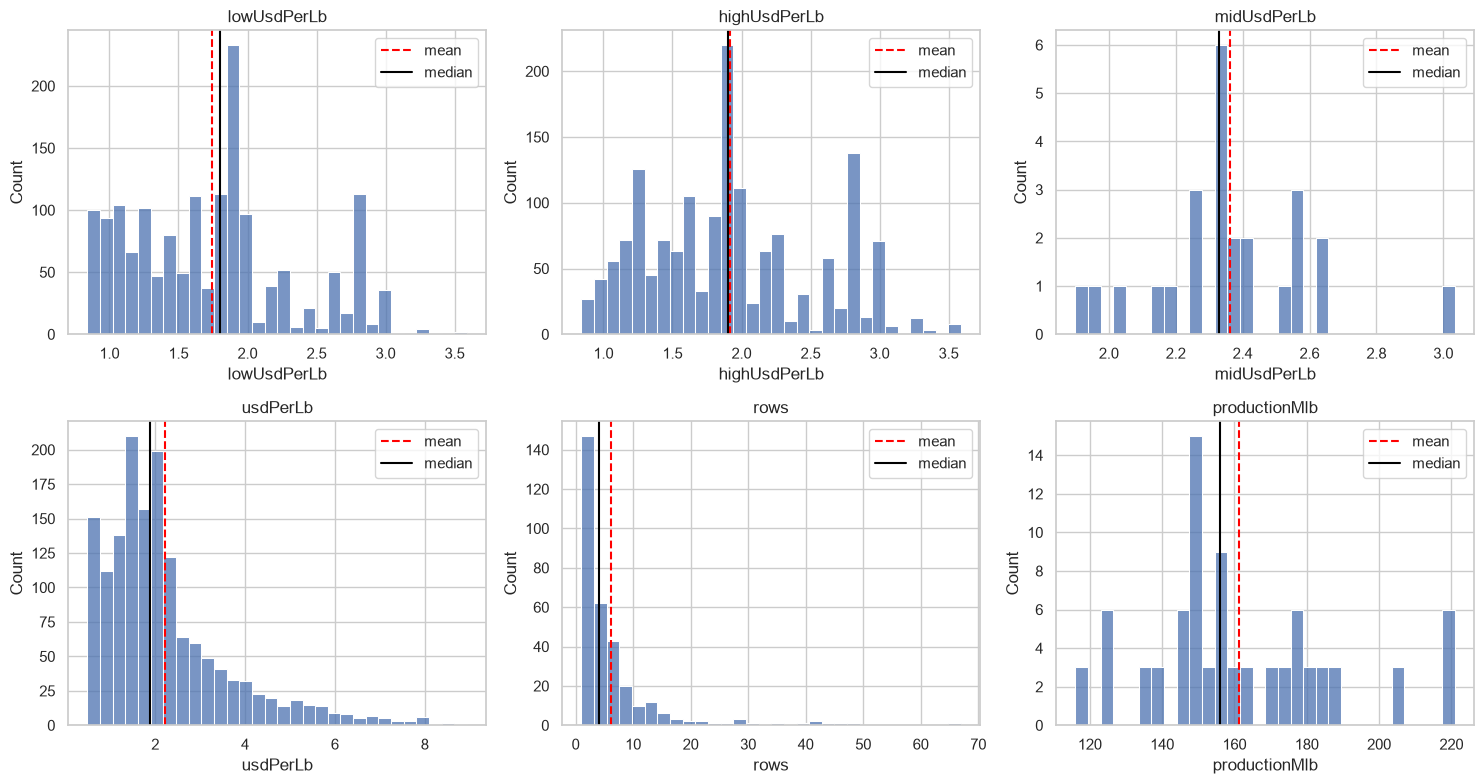

In [36]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), numeric_cols):
    sns.histplot(df[col].dropna(), bins=30, ax=ax)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label="mean")
    ax.axvline(df[col].median(), color="black", label="median")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

**What the histograms and statistics show**

| Variable | Min | Max | Mean | Median | Outliers |
|---|---|---|---|---|---|
| `lowUsdPerLb` | 0.84 | 3.59 | 1.74 | 1.80 | 7 |
| `highUsdPerLb` | 0.84 | 3.59 | 1.91 | 1.90 | 8 |
| `midUsdPerLb` | 1.90 | 3.04 | 2.36 | 2.33 | 1 |
| `usdPerLb` | 0.49 | 8.94 | 2.22 | 1.89 | 104 |
| `rows` | 1 | 67 | 6.19 | 4 | 27 |
| `productionMlb` | 116 | 221 | 161.18 | 156 | 6 |

- **Low and high prices** are spread over several humps instead of one clean peak, because they mix many kinds of honey and many countries. The few outliers are the highest prices (up to $3.59 per lb), for example a 2026 import of white orange blossom honey from India.
- **`usdPerLb`** is strongly right-skewed: the mean ($2.22) is well above the median ($1.89). The 104 outliers are not mistakes. They are retail prices from recent years, with the largest value ($8.94) for "area specialties" honey in retail in 2025.
- **`rows`** is also right-skewed. Most lines are based on only 1 to 4 quotes, and a few national summary lines are based on 40 or more (maximum 67).
- **`productionMlb`** ranges from 116 to 221 million pounds. The highest values (221) are from around 2000, and the lowest (116) is from 2025. The 6 outliers are the highest values near 221.
- **`midUsdPerLb`** has only 25 values (one per month), so its histogram is rough.

## 3. Categorical variables

Bar charts show how many rows fall in each category (top 15 shown when there are more)

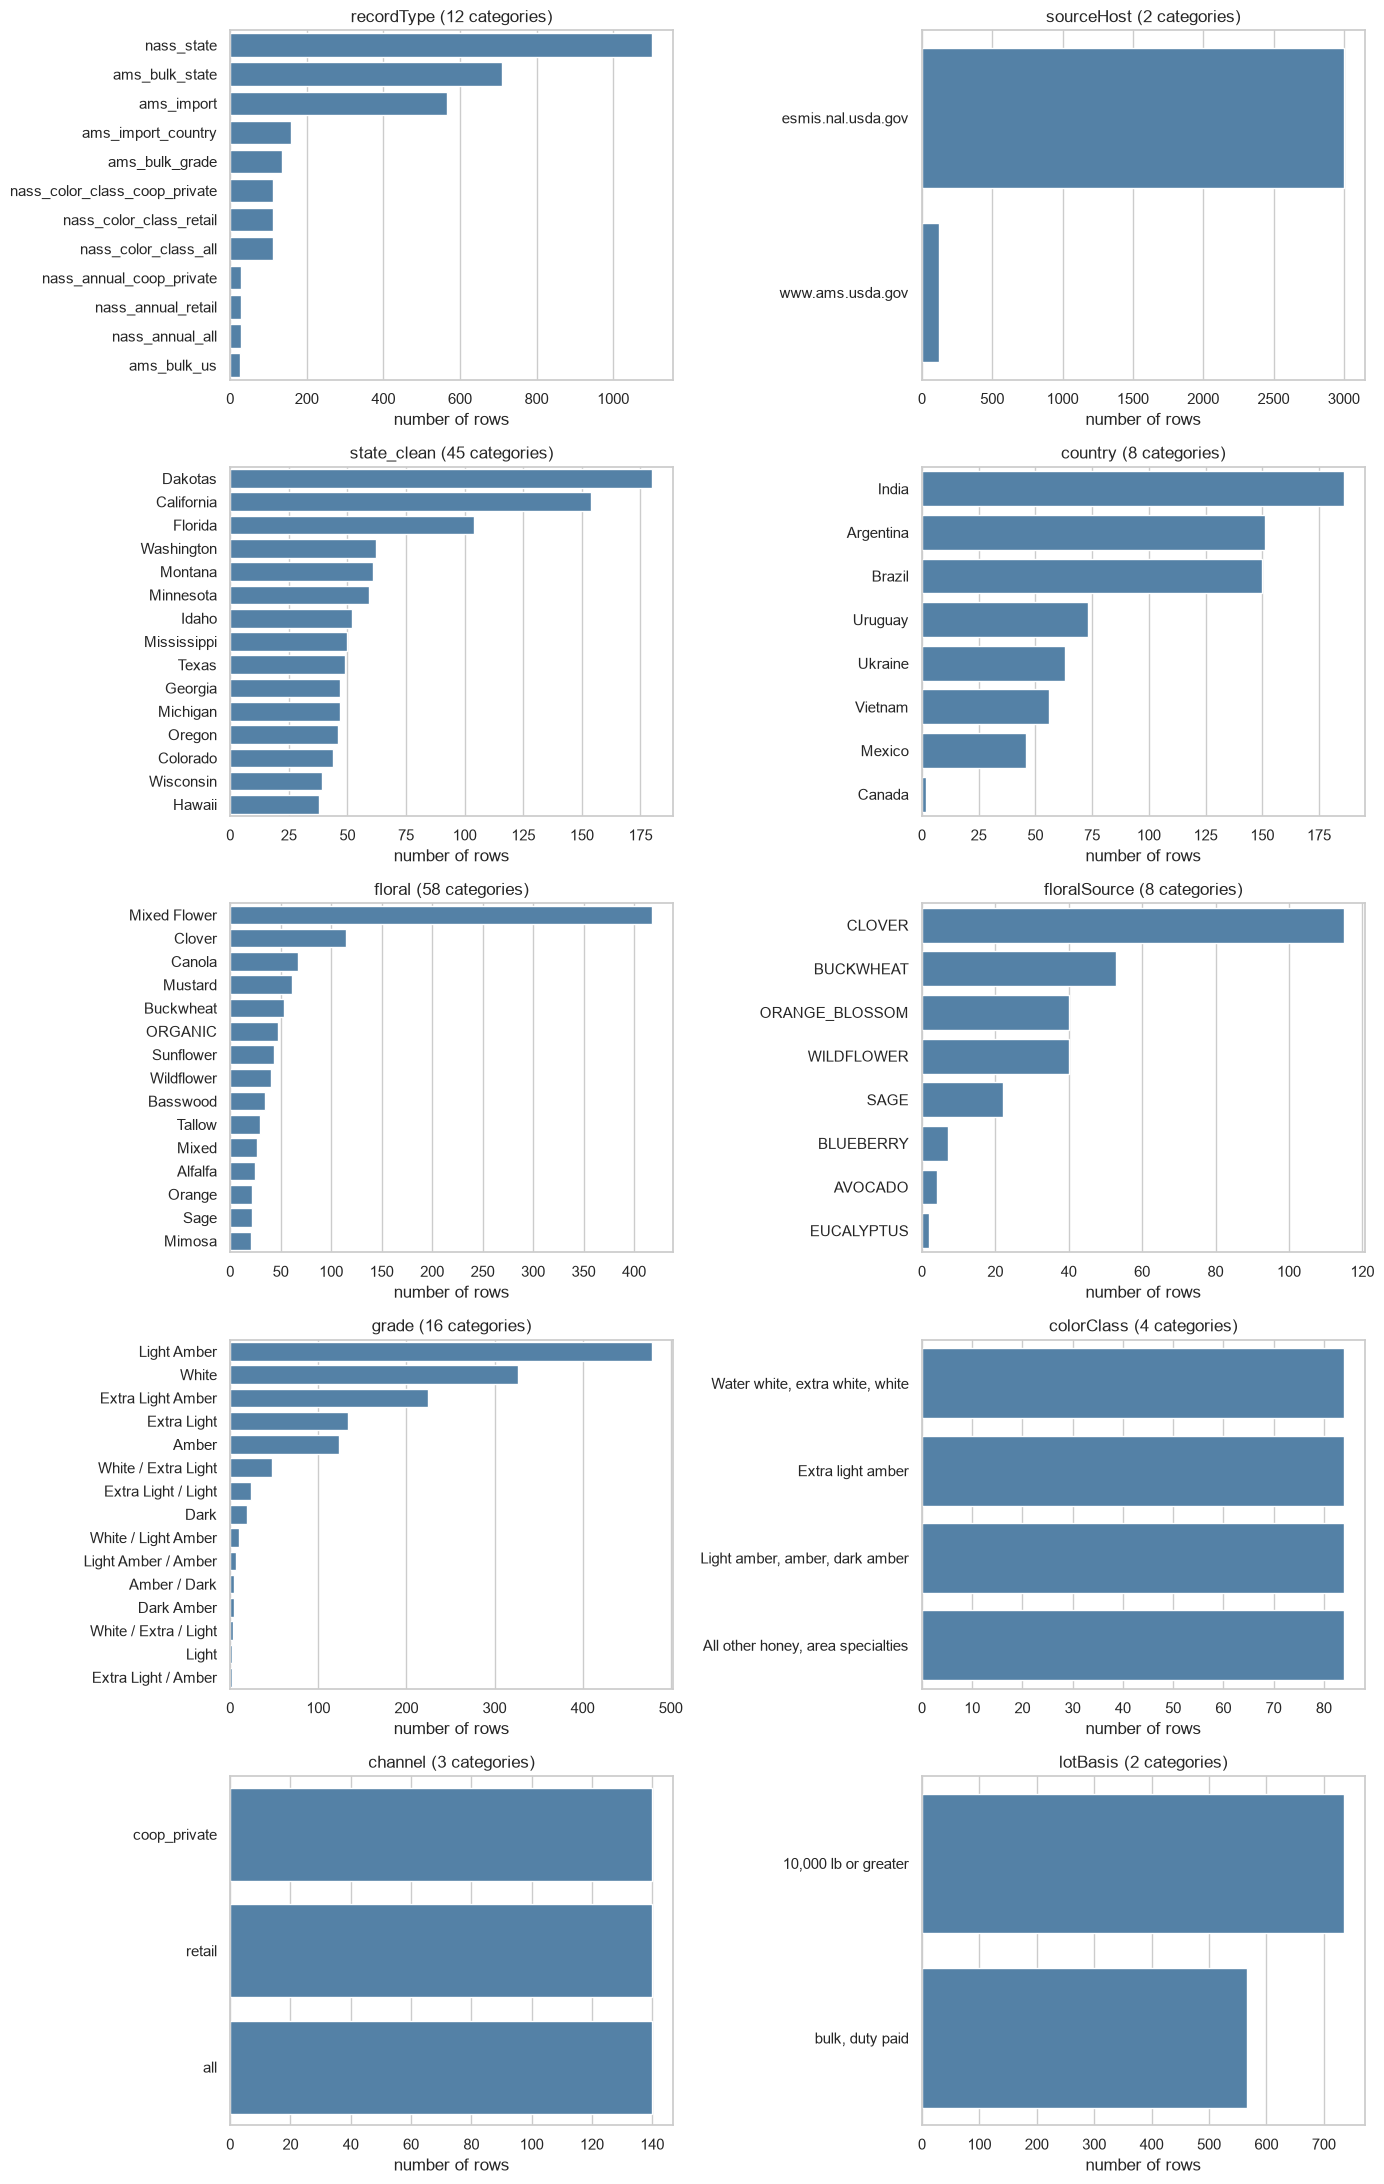

In [37]:
fig, axes = plt.subplots(5, 2, figsize=(14, 22))
for ax, col in zip(axes.flatten(), categorical_cols):
    counts = df[col].value_counts().head(15)
    sns.barplot(x=counts.values, y=counts.index, ax=ax, color="steelblue")
    ax.set_title(col + " (" + str(df[col].nunique()) + " categories)")
    ax.set_xlabel("number of rows")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**What the bar charts show**

- **`state_clean`:** 45 states or regions. "Dakotas" is the most common (180 rows).
- **`country`** (imports only): 8 countries. India is the most common (186 rows) and Canada is the least (2).
- **`floral`:** 58 flower sources. "Mixed Flower" is the most common (418 rows), and many sources appear only once.
- **`grade`:** 16 color grades. "Light Amber" is the most common (479 rows).
- **`channel`:** 3 channels (`all`, `coop_private`, `retail`), with exactly 140 rows each.
- **`colorClass`:** 4 NASS color classes, with exactly 84 rows each.
- **`lotBasis`:** "10,000 lb or greater" (735 rows) and "bulk, duty paid" (567 rows).
- **`floralSource`** and **`sourceHost`** are mostly empty or dominated by one value (96% of rows come from `esmis.nal.usda.gov`).

## 4. Difference in money variables

The variables have different units (dollars, counts, million pounds), so on one axis the dollar columns would look flat. To put them side by side I standardize each one (subtract its mean, divide by its standard deviation), so 0 is the average and each unit is one standard deviation.

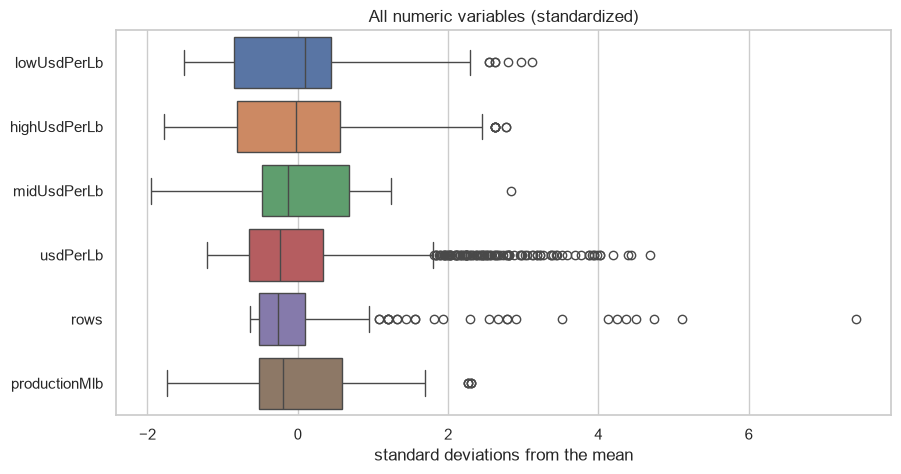

In [38]:
standardized = (df[numeric_cols] - df[numeric_cols].mean()) / df[numeric_cols].std()

plt.figure(figsize=(10, 5))
sns.boxplot(data=standardized, orient="h")
plt.title("All numeric variables (standardized)")
plt.xlabel("standard deviations from the mean")
plt.show()

**What the box plot shows:** the dots beyond the whiskers are the outliers counted earlier. `usdPerLb` has a alot of outliers (the recent retail prices), and `rows` has a few extreme values. The low, high and mid prices and `productionMlb` have few or no outliers

## 5. Scatter plot matrix:

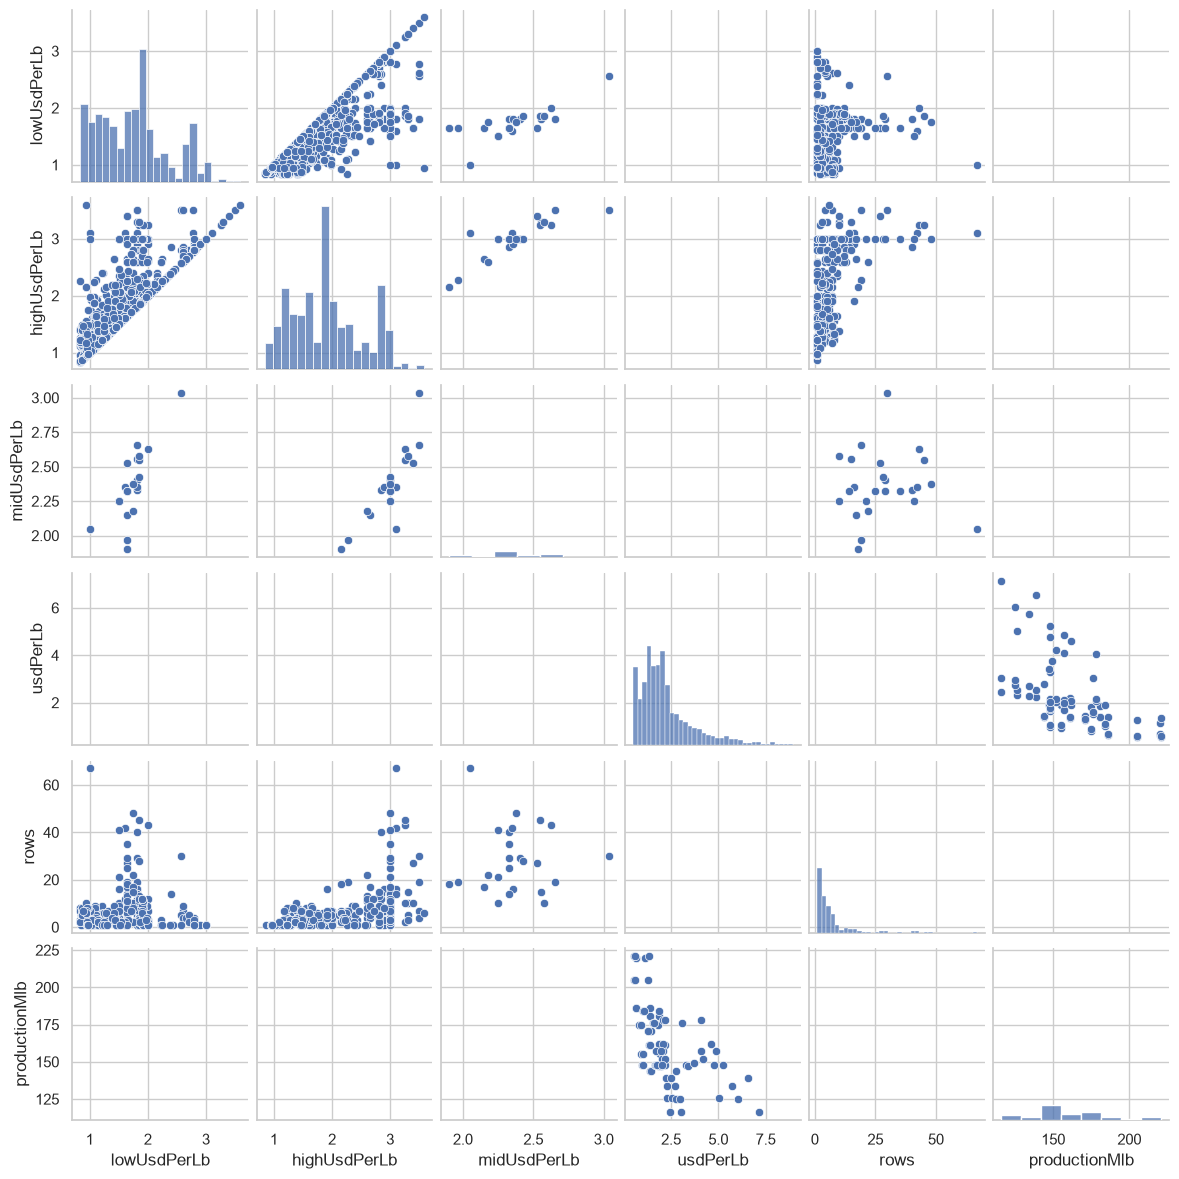

In [39]:
sns.pairplot(df[numeric_cols], height=2)
plt.show()

**What the scatter plots show**
- **Low vs high price** forms a tight line close to the diagonal: when the low price is higher, so is the high price. Many points sit exactly on the diagonal because many report lines quote a single price (low = high).
- **`usdPerLb` vs `productionMlb`** has a negative slope as years with higher production tend to have lower prices.
- **`rows`** has no clear relationship with price. Lines based on many quotes are bunched at the bottom of the plot, while the price spread is wide.
- The blank panels are pairs of variables that never appear in the same row of the file

## 6. Categorical vs categorical

To compare two categorical variables I counted how often each pair occurs and showed the table as a heat map. A third view aggregates a nmean price over two categorical variables.

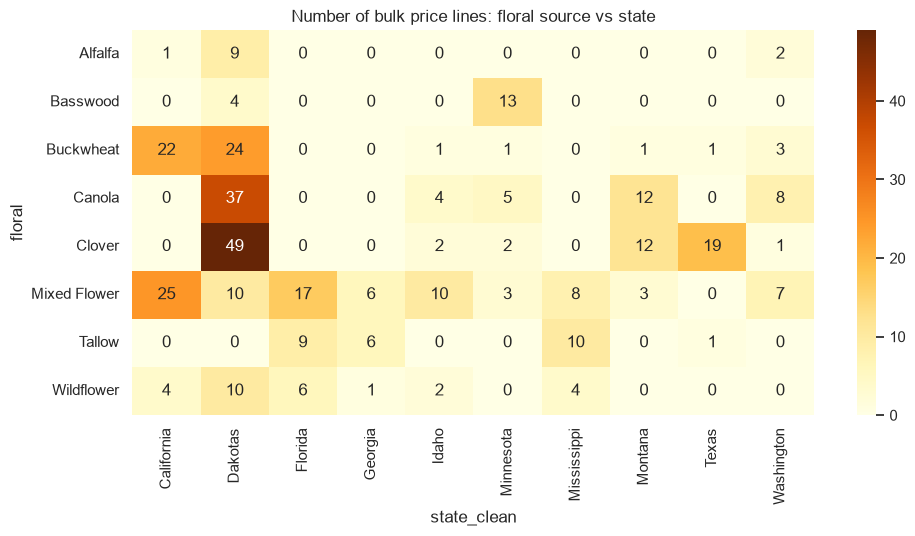

In [ ]:
# Floral source vs state in the AMS bulk state table
bulk = df[df["recordType"] == "ams_bulk_state"]
top_floral = bulk["floral"].value_counts().head(8).index
top_states = bulk["state_clean"].value_counts().head(10).index
subset = bulk[bulk["floral"].isin(top_floral) & bulk["state_clean"].isin(top_states)]

plt.figure(figsize=(11, 5))
sns.heatmap(pd.crosstab(subset["floral"], subset["state_clean"]), annot=True, fmt="d", cmap="YlOrBr")
plt.title("Number of bulk price lines: floral source vs state")
plt.show()

**Floral source vs state:** the Dakotas comes in lead with the bulk reports for clover (49 price lines), canola (37) and buckwheat (24). California is mostly buckwheat (22) and mixed flower (25). Tallow shows up only in the Southeast (Florida, Georgia, Mississippi), basswood is mostly Minnesota (13 of 17 lines), and Texas appears mainly for clover (19). So the flower source tells you a lot about where the honey comes from.

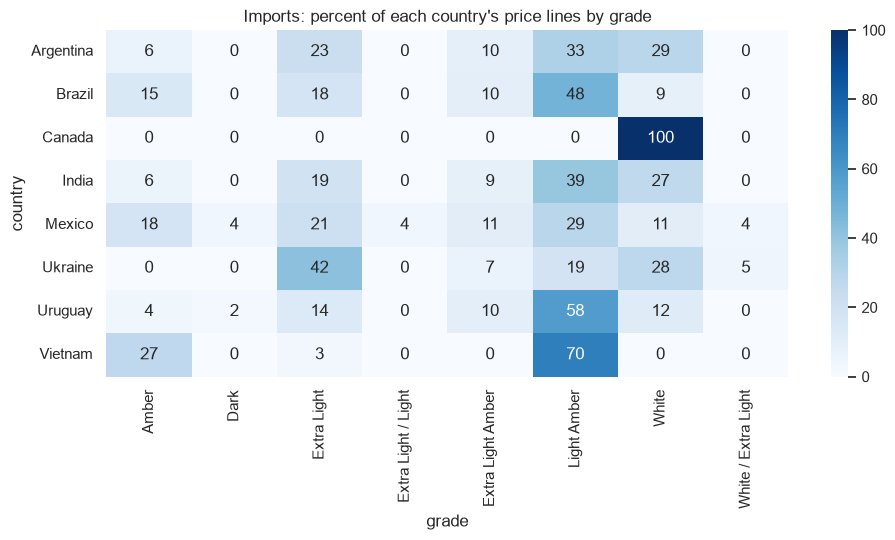

In [41]:
# Import country vs honey grade (percent of each country's price lines)
imports = df[df["recordType"] == "ams_import"]
top_grades = imports["grade"].value_counts().head(8).index
sub = imports[imports["grade"].isin(top_grades)]

table = pd.crosstab(sub["country"], sub["grade"], normalize="index") * 100
plt.figure(figsize=(11, 4.5))
sns.heatmap(table, annot=True, fmt=".0f", cmap="Blues")
plt.title("Imports: percent of each country's price lines by grade")
plt.show()

**Import country vs grade** (each row is a percent of that country's lines, and only the 8 most common grades are shown, so rows don't add to 100): light amber is the most common grade for Vietnam (70%), Uruguay (58%), Brazil (48%) and India (39%). Ukraine is mostly extra light (42%). Canada is 100% white, but it has only 2 lines, so that percentage means little.

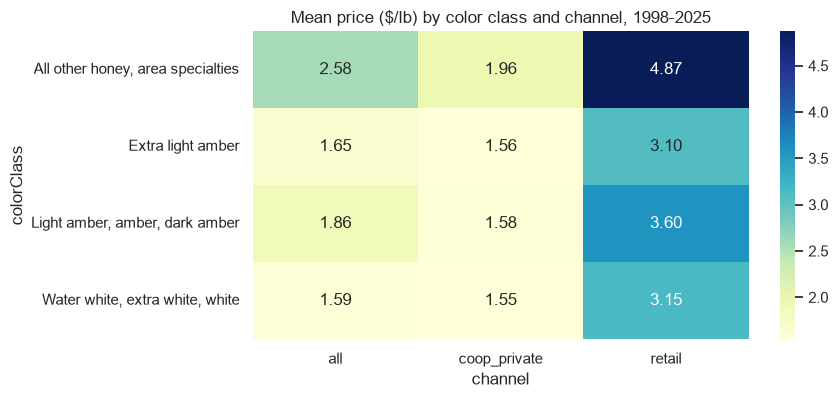

In [ ]:
# mean price by color class and channel (NASS)
nass = df[df["recordType"].str.startswith("nass_color_class")]
mean_price = nass.pivot_table(index="colorClass", columns="channel", values="usdPerLb", aggfunc="mean")

plt.figure(figsize=(8, 4))
sns.heatmap(mean_price, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Mean price ($/lb) by color class and channel, 1998-2025")
plt.show()

**Aggregate view:** in every color class, retail prices are two to 2 1/2 times the co-op/private prices (for example $3.10 vs $1.56 for extra light amber, $4.87 vs $1.96 for area specialties). "All other honey, area specialties" is the most expensive class in every channel ($4.87 at retail)

## 7. Categorical vs numeric

Here color or grouping carries the categorical variabless

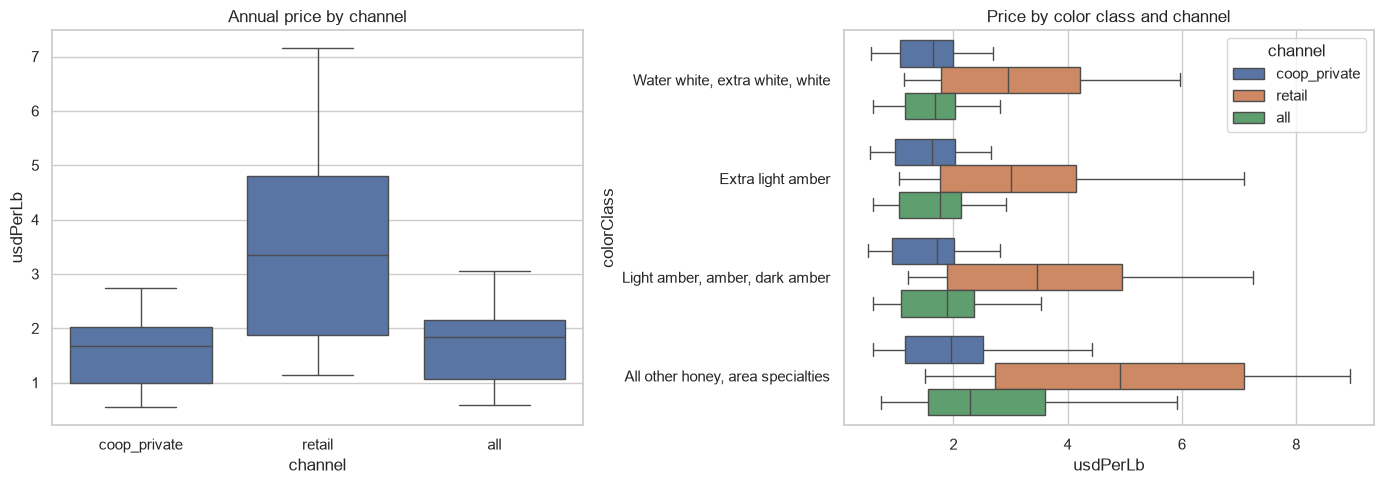

In [43]:
# Price by sales channel and by color class (NASS)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
annual = df[df["recordType"].isin(["nass_annual_all", "nass_annual_coop_private", "nass_annual_retail"])]
sns.boxplot(data=annual, x="channel", y="usdPerLb", ax=axes[0])
axes[0].set_title("Annual price by channel")
sns.boxplot(data=nass, x="usdPerLb", y="colorClass", hue="channel", ax=axes[1])
axes[1].set_title("Price by color class and channel")
plt.tight_layout()
plt.show()

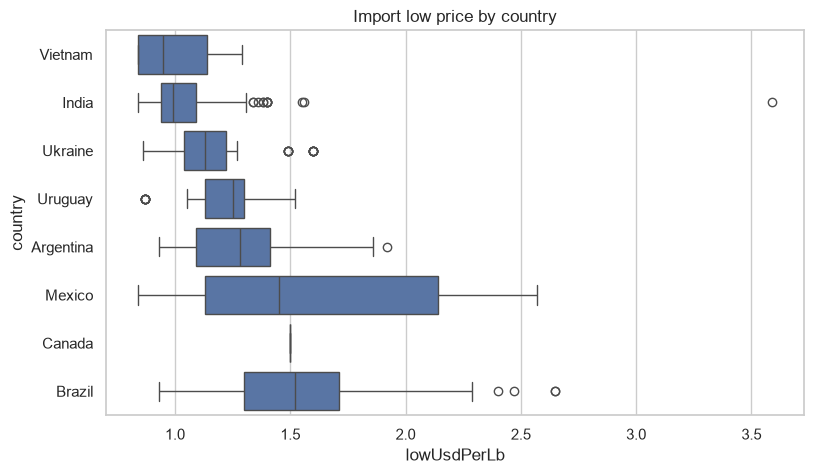

In [44]:
# Import price by country
imports = df[df["recordType"].isin(["ams_import", "ams_import_country"]) & df["lowUsdPerLb"].notna()]
order = imports.groupby("country")["lowUsdPerLb"].median().sort_values().index

plt.figure(figsize=(9, 5))
sns.boxplot(data=imports, x="lowUsdPerLb", y="country", order=order)
plt.title("Import low price by country")
plt.show()

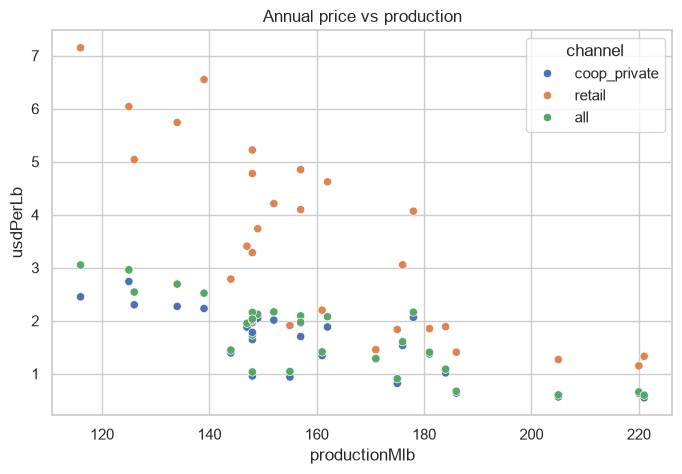

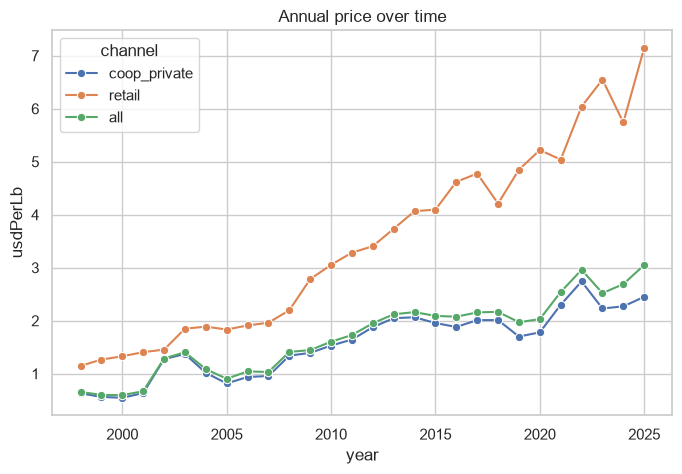

In [45]:
# Price vs production, colored by channel
plt.figure(figsize=(8, 5))
sns.scatterplot(data=annual, x="productionMlb", y="usdPerLb", hue="channel")
plt.title("Annual price vs production")
plt.show()

# Price over time, colored by channel
plt.figure(figsize=(8, 5))
annual = annual.copy()
annual["year"] = annual["period"].astype(int)
sns.lineplot(data=annual, x="year", y="usdPerLb", hue="channel", marker="o")
plt.title("Annual price over time")
plt.show()

**What these show**
- **By channel:** retail prices are higher and more spread out than co-op/private prices (retail median about $3.34 per lb vs about $1.67 for co-op/private).
- **By country:** import prices differ by origin. Vietnam has the lowest median low price (about $0.95 per lb) and Brazil the highest (about $1.52 per lb). Mexico has the widest spread of prices, and Canada has only 2 lines (shown as a single line on the plot).
- **Over time:** prices rose in every channel from 1998 to 2025. The all channel price went from about $0.66 per lb to $3.05 per lb, about 4.7 times higher, while production fell from 220 to 116 million lb.

## 8. Summary of values
- Prices rose a lot between 1998 and 2025, and retail prices are roughly two to two and a half times co-op/private prices.
- Higher production goes with lower prices, and lower production with higher prices.
- Most "outliers" are recent retail prices
- Import prices differ by country of origin, and low and high quotes move together.
- The file is several USDA tables stacked together, so... many columns are empty for most rows, and some variable pairs never appear on the same row.

## 9. Conclusion analysis of the USDA honey data

**Prices rose as production fell.** The NASS average price went from $0.66/lb
in 1998 to $3.05/lb in 2025, while national production dropped from
220 to 116 million pounds.

**Sales channel matters more than honey type.** Retail prices run roughly two
to two and a half times co-op/private prices ($3.34/lb vs $1.67/lb median), and
that is true for every color class. Color shifts prices far less than
where the honey is sold.

The largest ($8.94/lb) is retail specialty honey in 2025. 
